# 1-hour-ahead mobile traffic forecasting: Telecom Italia, Milan

**Goal.** Predict the internet activity of a city zone one hour ahead from its recent history, compare simple baselines with tree-based models, and quantify uncertainty with prediction intervals.

**Data.** Telecom Italia Big Data Challenge (Milan): internet activity per zone every 10 minutes. This notebook uses 204 of the 10,000 zones and 14 days (1-14 Nov 2013). Values are normalised by the data provider and have no units. License (ODbL 1.0) and citation are in the README.

**Protocol.** Time-based split: train on 1-7 Nov, test on 8-14 Nov. Error metric: per-zone mean absolute error divided by the zone's mean level (in %), then the median across zones. Dividing by the level makes zones of very different size comparable.

**Run order.** Run `scripts/build_dataset.py` once to create `data/traffic_204_zones.csv`, then run this notebook from top to bottom.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

DATA_FILE = Path("../data/traffic_204_zones.csv")
H = 6                      # forecast horizon: 6 steps x 10 min = 1 hour
STEPS_PER_DAY = 144        # 24 h x 6 steps per hour
SPLIT = "2013-11-08"       # train: before this date, test: from this date on

plt.rcParams["figure.dpi"] = 110

## 1. Load the data

The CSV has one row per zone and 10-minute interval. We pivot it into a table with time as rows and zones as columns, put it on a regular 10-minute grid, and interpolate gaps of at most three steps (if any).

In [2]:
traffic = pd.read_csv(DATA_FILE, parse_dates=["time"])
print("rows:", len(traffic), "| zones:", traffic["cell"].nunique(),
      "|", traffic["time"].min(), "to", traffic["time"].max())

wide = (traffic.pivot(index="time", columns="cell", values="internet")
        .sort_index().asfreq("10min"))
print("missing values before interpolation:", int(wide.isna().sum().sum()))
wide = wide.interpolate(limit=3)

rows: 411264 | zones: 204 | 2013-11-01 00:00:00 to 2013-11-14 23:50:00
missing values before interpolation: 0


## 2. Look at two zones

One high-traffic and one low-traffic zone. Note the daily rhythm (quiet nights, busy days), the very different scale of the two zones (the values are unit-less, so only the pattern and relative size matter), and the occasional sharp spikes.

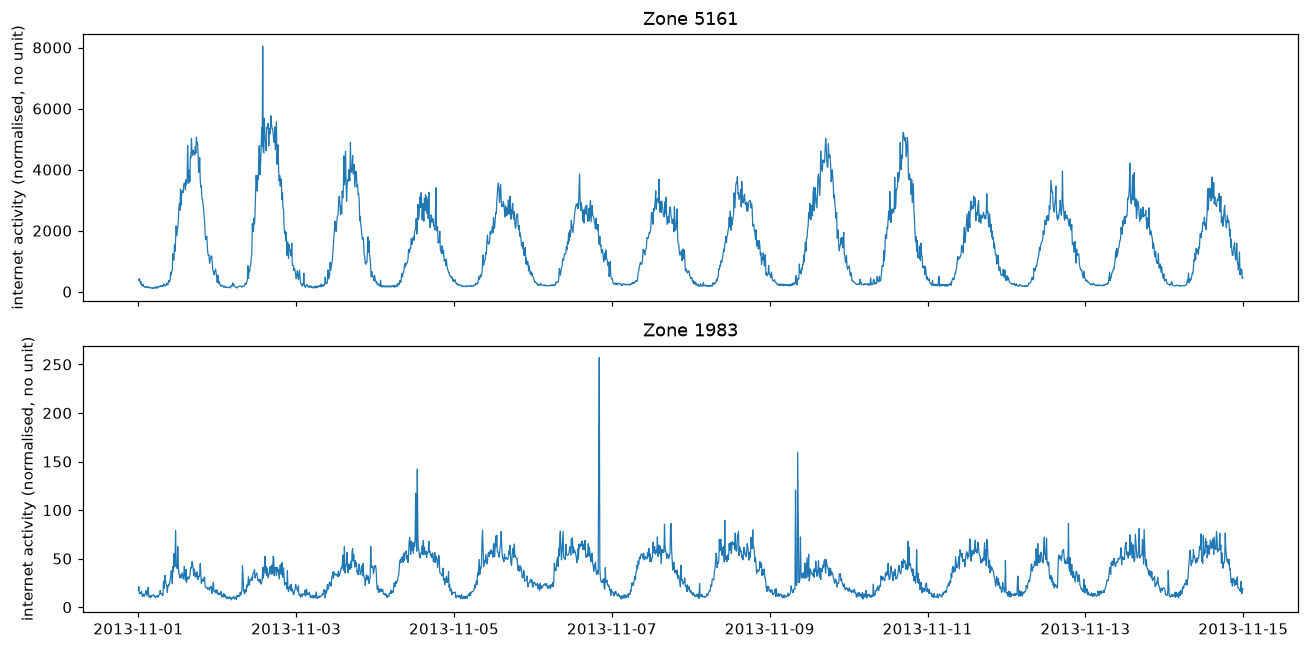

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, zone in zip(axes, [5161, 1983]):
    ax.plot(wide.index, wide[zone], lw=0.8)
    ax.set_title(f"Zone {zone}")
    ax.set_ylabel("internet activity (normalised, no unit)")
plt.tight_layout()
plt.show()

## 3. Features and time-based split

For every 10-minute step `t` we predict the activity at `t`, using only information available one hour earlier:

| feature | meaning |
|---|---|
| `lag_h`, `lag_h1`, `lag_h2` | activity 1 h, 1 h 10 min and 1 h 20 min before `t` (recent level and trend) |
| `lag_day` | activity at the same time the day before |
| `hour` | time of day |
| `dow` | day of week |

Each zone is divided by its mean level **over the training period only**, so one model can learn the *shape* of the day for all zones. Splitting by time (never randomly) avoids leaking the future into training. `lag_week` is not used: with one week of training data there is no week-ago history.

In [4]:
scale = wide[wide.index < SPLIT].mean()   # per-zone level, training period only
norm = wide / scale

def make_features(s):
    df = pd.DataFrame({"y": s})
    df["lag_h"]   = s.shift(H)
    df["lag_h1"]  = s.shift(H + 1)
    df["lag_h2"]  = s.shift(H + 2)
    df["lag_day"] = s.shift(STEPS_PER_DAY)
    df["hour"] = s.index.hour + s.index.minute / 60
    df["dow"]  = s.index.day_of_week
    return df

long = pd.concat([make_features(norm[c]).assign(cell=c) for c in norm.columns])
long = long.dropna(subset=["y", "lag_h", "lag_day"])

FEATS = ["lag_h", "lag_h1", "lag_h2", "lag_day", "hour", "dow"]
train = long[long.index < SPLIT]
test = long[long.index >= SPLIT].copy()
print("train rows:", len(train), "| test rows:", len(test))

train rows: 176256 | test rows: 205632


## 4. Baselines and models

Two naive baselines (no training): *same time yesterday* and *same as one hour ago*. Three tree-based models: a single decision tree, a random forest and gradient boosting (hyper-parameters are reasonable defaults and were not tuned).

In [5]:
def per_zone_pct_error(y_true, y_pred, cells):
    err = pd.Series(np.abs(y_true - y_pred)).groupby(cells).mean()
    level = pd.Series(y_true).groupby(cells).mean()
    return err / level * 100

X_train, y_train = train[FEATS], train["y"]
X_test = test[FEATS]
y_true = test["y"].to_numpy()
cells = test["cell"].to_numpy()

dt = DecisionTreeRegressor(max_depth=8, min_samples_leaf=50, random_state=0).fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=0).fit(X_train, y_train)
gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0).fit(X_train, y_train)
test["pred"] = gb.predict(X_test)

predictions = {
    "same time yesterday":  test["lag_day"].to_numpy(),
    "same as one hour ago": test["lag_h"].to_numpy(),
    "single decision tree": dt.predict(X_test),
    "random forest":        rf.predict(X_test),
    "gradient boosting":    test["pred"].to_numpy(),
}
zone_errors = {name: per_zone_pct_error(y_true, p, cells) for name, p in predictions.items()}

results = pd.Series({name: e.median() for name, e in zone_errors.items()}).round(1)
print("Median error across zones, % of the zone's mean level:")
print(results.to_string())

better = (zone_errors["gradient boosting"] < zone_errors["same time yesterday"]).mean() * 100
print(f"\nGradient boosting beats 'same time yesterday' in {better:.0f}% of zones")

Median error across zones, % of the zone's mean level:
same time yesterday     21.7
same as one hour ago    19.1
single decision tree    15.3
random forest           14.6
gradient boosting       14.5

Gradient boosting beats 'same time yesterday' in 99% of zones


## 5. Error by day of week

How do the methods behave on each day of the test week? Each weekday appears once in the test week, so treat this as an observation for this particular week, not a general rule.

In [6]:
names = ["same time yesterday", "same as one hour ago", "gradient boosting"]
errs = pd.DataFrame({"cell": cells, "dow": test["dow"].to_numpy(), "y": y_true})
for n in names:
    errs[n] = np.abs(y_true - predictions[n])

g = errs.groupby(["cell", "dow"])
by_zone_day = g[names].mean().div(g["y"].mean(), axis=0) * 100
by_dow = by_zone_day.groupby("dow").median().round(1)
by_dow.index = by_dow.index.map(dict(enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])))
by_dow

,same time yesterday,same as one hour ago,gradient boosting
dow,,,
Mon,26.9,18.2,14.0
Tue,17.3,19.0,14.0
Wed,17.7,18.9,13.9
Thu,18.2,19.3,13.8
Fri,18.7,18.9,13.8
Sat,25.4,19.1,15.3
Sun,21.6,18.9,14.6


## 6. Prediction intervals (quantile regression)

Instead of one number, we also predict the 5th and 95th percentiles. If the intervals are well calibrated, about 90% of the actual values should fall between them (the *coverage*).

Coverage of the 5-95% interval: 89.1% (target about 90%)
Median interval width: 64.0% of the zone's mean level


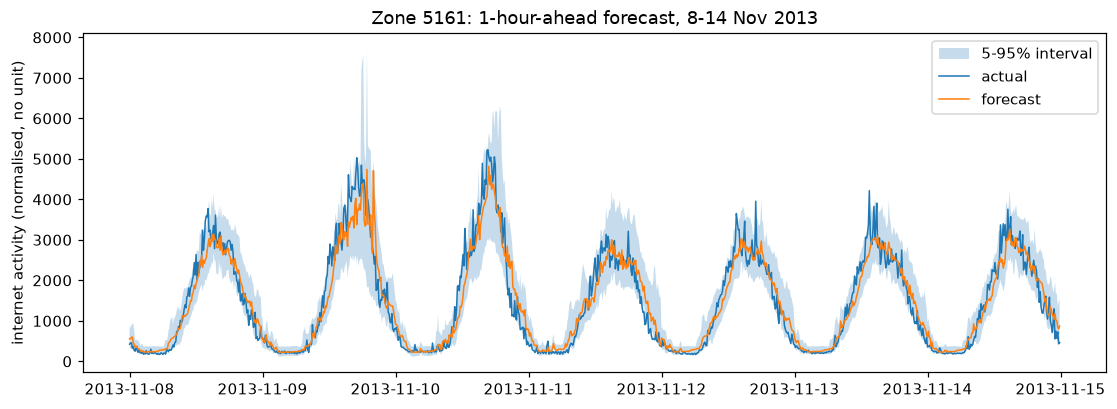

In [7]:
q_lo = HistGradientBoostingRegressor(loss="quantile", quantile=0.05, max_iter=300,
                                     learning_rate=0.05, random_state=0).fit(X_train, y_train)
q_hi = HistGradientBoostingRegressor(loss="quantile", quantile=0.95, max_iter=300,
                                     learning_rate=0.05, random_state=0).fit(X_train, y_train)
test["lo"] = np.clip(q_lo.predict(X_test), 0, None)
test["hi"] = q_hi.predict(X_test)

inside = (test["y"] >= test["lo"]) & (test["y"] <= test["hi"])
zone_mean = test.groupby("cell")["y"].transform("mean")
width = ((test["hi"] - test["lo"]) / zone_mean).median() * 100
print(f"Coverage of the 5-95% interval: {inside.mean() * 100:.1f}% (target about 90%)")
print(f"Median interval width: {width:.1f}% of the zone's mean level")

zone = 5161
d = test[test["cell"] == zone]
k = scale[zone]    # back to the original (unit-less) scale of this zone
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(d.index, d["lo"] * k, d["hi"] * k, alpha=0.25, label="5-95% interval")
ax.plot(d.index, d["y"] * k, lw=1, label="actual")
ax.plot(d.index, d["pred"] * k, lw=1, label="forecast")
ax.set_title(f"Zone {zone}: 1-hour-ahead forecast, 8-14 Nov 2013")
ax.set_ylabel("internet activity (normalised, no unit)")
ax.legend()
plt.show()

## 7. Which features does the model use?

Permutation importance: shuffle one feature at a time and measure how much the error grows. Units are normalised (1.0 = the zone's mean level). The three "lag around one hour" features are correlated, so each one's individual importance is understated.

In [8]:
sample = test.sample(min(30000, len(test)), random_state=0)
r = permutation_importance(gb, sample[FEATS], sample["y"],
                           scoring="neg_mean_absolute_error",
                           n_repeats=5, random_state=0, n_jobs=-1)
importance = pd.Series(r.importances_mean, index=FEATS).sort_values(ascending=False)
importance.round(3)

lag_h      0.066
hour       0.046
lag_h2     0.029
lag_day    0.027
lag_h1     0.024
dow        0.008
dtype: float64

## 8. Limitations and next steps

**Limitations**
- Training uses a single week and testing a single week, so results may change on other weeks; 1 Nov 2013 was a public holiday in Italy.
- 204 of 10,000 zones were used (a random sample with a fixed seed plus four zones inspected earlier).
- Only a 1-hour horizon; hyper-parameters were not tuned.
- Values are normalised by the provider, so errors are relative (% of a zone's mean level) and cannot be converted to real traffic volumes.
- The day-of-week table covers one week; the weekday effects it shows are observations, not tested conclusions.
- Interval coverage is an average over all zones and times; it can be higher or lower for a particular zone or hour.

**Next steps**
- Train on several weeks and add a "same time last week" feature.
- Evaluate on several test weeks (rolling-origin validation) and tune hyper-parameters.
- Check calibration of the intervals per zone and per time of day.
- Investigate the sharp spikes (events or measurement artefacts).
- Try other horizons and neural sequence models.